# Cutting products without cutting margin

This notebook produces every number and chart in the write-up ([README.md](README.md)).

The data is real: purchases of Smirnoff products by Iowa stores from the state's wholesale warehouse, published by the Iowa Department of Revenue, Alcoholic Beverages Division, on the Iowa Data Hub (CC BY 4.0). `get_data.py` rebuilds the files in `data/`. The calculations live in `cuts.py`.

In [1]:
import pandas as pd
from IPython.display import Image

import cuts as c
import charts

pd.options.display.float_format = "{:,.2f}".format
r = c.run()          # loads the data and works out the three lists of products
f = c.facts(r)       # every number quoted in the write-up
p = r["p"]           # one row per product
print(f"{f['lines']:,} invoice lines, {f['stores']:,} stores, {f['products']} products, ${f['sales']:,.0f} in 2025")
r["d"]["lines"].head(5)

77,466 invoice lines, 2,095 stores, 51 products, $10,098,719 in 2025


,invoice_id,ordered_on,store_no,store_name,store_city,county_name,item_no,im_desc,pack,bottle_volume_ml,sales_bottles,sales_dollars,sales_liters
0,INV-78192100025,2025-01-01,2505,HY-VEE WINE AND SPIRITS (1038) / BOONE,BOONE,BOONE,37996,SMIRNOFF 80PRF,12,750.00,12.00,148.56,9.00
1,INV-78192200052,2025-01-02,2548,HY-VEE FOOD STORE (1011) / ALTOONA,ALTOONA,POLK,37996,SMIRNOFF 80PRF,12,750.00,12.00,148.56,9.00
2,INV-78192300023,2025-01-02,4135,FAREWAY STORES #925 / ALTOONA,ALTOONA,POLK,77988,SMIRNOFF SPICY TAMARIND,12,750.00,2.00,24.76,1.50
3,INV-78192400019,2025-01-02,4971,FAREWAY STORES #138 / PLEASANT HILL,PLEASANT HILL,POLK,37994,SMIRNOFF 80PRF,24,375.00,6.00,44.94,2.25
4,INV-78192400028,2025-01-02,4971,FAREWAY STORES #138 / PLEASANT HILL,PLEASANT HILL,POLK,77674,SMIRNOFF GREEN APPLE,12,750.00,6.00,74.28,4.50


## Step 1. Draw the obvious line

In [2]:
print(f"Biggest product: {f['top_product_share']:.1%} of sales.  Five biggest: {f['top5_share']:.1%}.  Smaller-selling half: {f['bottom_half_share']:.1%}.")
print(f"Ten smallest: ${f['smallest_all_sales']:,.0f}, {f['smallest_all_share']:.1%} of sales.")
p[["name", "sales", "share", "stores", "sales_2024"]].tail(10).style.format({"sales": "${:,.0f}", "share": "{:.2%}", "sales_2024": "${:,.0f}"})

Biggest product: 28.0% of sales.  Five biggest: 59.0%.  Smaller-selling half: 9.6%.
Ten smallest: $200,765, 2.0% of sales.


,name,sales,share,stores,sales_2024
item_no,,,,,
78079,"Zero Sugar Watermelon & Mint, 750 ml","$32,406",0.32%,125,"$30,133"
102694,"Variety Pack, minis x120","$31,330",0.31%,173,$0
78128,"Pink Lemonade, minis x10","$27,596",0.27%,259,"$26,663"
76829,"Blue Raspberry Lemonade, 1.75 L","$25,175",0.25%,76,"$25,206"
76831,"Blue Raspberry Lemonade, minis x10","$24,082",0.24%,244,"$20,090"
78291,"Peach Lemonade, 1.75 L","$15,712",0.16%,57,"$15,292"
78292,"Peach Lemonade, minis x10","$15,399",0.15%,176,"$21,125"
77681,"Kissed Caramel, minis x10","$13,853",0.14%,223,$0
78557,"Electric Guava, minis x10","$13,205",0.13%,235,$0


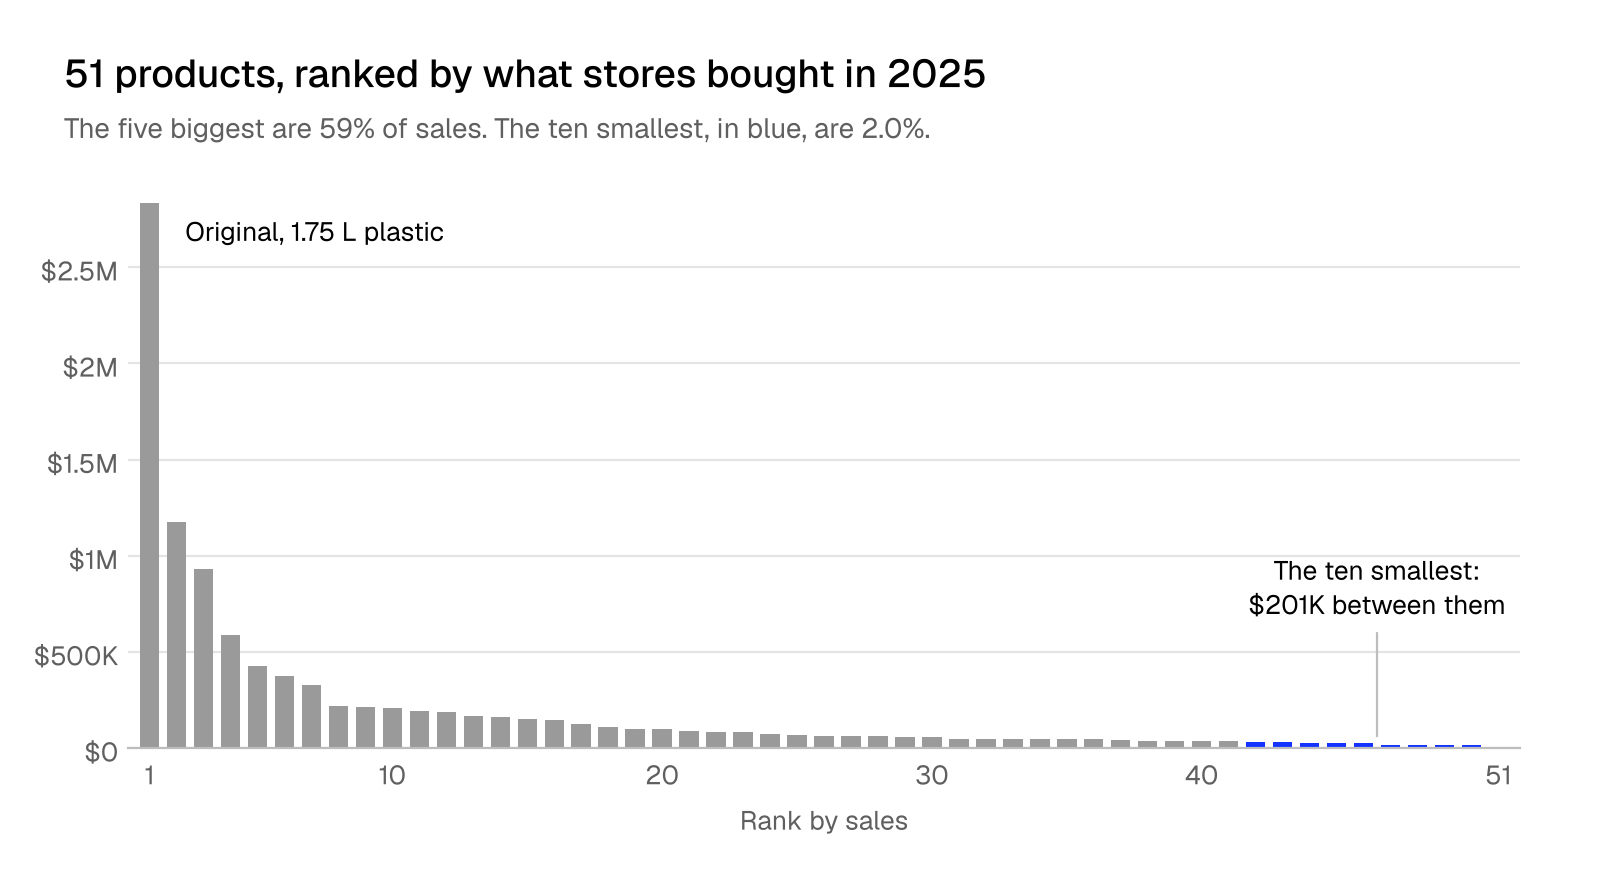

In [3]:
Image(charts.chart_tail(r, f), width=760)

## Step 2. Check what a "bottle" is

`per_liter_as_filed` divides sales by the liters column in the state's file. `per_liter` uses the pack size from the state's product list: a mini "bottle" is a sleeve of ten.

In [4]:
minis = p[p["bottle_ml"] == 50][["name", "units", "inner_pack", "unit_ml", "state_liters", "liters", "per_liter_as_filed", "per_liter"]]
minis.style.format({"units": "{:,.0f}", "inner_pack": "{:.0f}", "unit_ml": "{:,.0f}", "state_liters": "{:,.0f}", "liters": "{:,.0f}", "per_liter_as_filed": "${:.2f}", "per_liter": "${:.2f}"})

,name,units,inner_pack,unit_ml,state_liters,liters,per_liter_as_filed,per_liter
item_no,,,,,,,,
37991,"Original, minis x10","61,774",10,500,"2,713","30,887",$157.35,$13.82
77955,"Red, White & Berry, minis x10","6,462",10,500,283,"3,231",$157.92,$13.81
102694,"Variety Pack, minis x120",378,120,"6,000",17,"2,268",$1859.36,$13.81
78128,"Pink Lemonade, minis x10","3,997",10,500,174,"1,998",$158.55,$13.81
76831,"Blue Raspberry Lemonade, minis x10","3,489",10,500,153,"1,744",$157.09,$13.80
78292,"Peach Lemonade, minis x10","2,231",10,500,96,"1,116",$160.74,$13.80
77681,"Kissed Caramel, minis x10","2,016",10,500,74,"1,008",$186.07,$13.74
78557,"Electric Guava, minis x10","1,914",10,500,87,957,$151.70,$13.80
77987,"Spicy Tamarind, minis x10",290,10,500,14,145,$138.40,$13.84


## Step 3. See what a liter earns

In [5]:
c.by_size(p).style.format({"unit_ml": "{:,.0f}", "sales": "${:,.0f}", "liters": "{:,.0f}", "per_liter": "${:.2f}", "share_of_sales": "{:.1%}"})

,unit_ml,products,sales,liters,per_liter,share_of_sales
0,200,1,"$146,653","7,706",$19.03,1.5%
1,375,1,"$1,175,589","58,912",$19.95,11.6%
2,500,8,"$567,661","41,086",$13.82,5.6%
3,750,28,"$4,278,125","258,824",$16.53,42.4%
4,"1,000",6,"$864,123","62,283",$13.87,8.6%
5,"1,750",6,"$3,035,236","239,680",$12.66,30.1%
6,"6,000",1,"$31,330","2,268",$13.81,0.3%


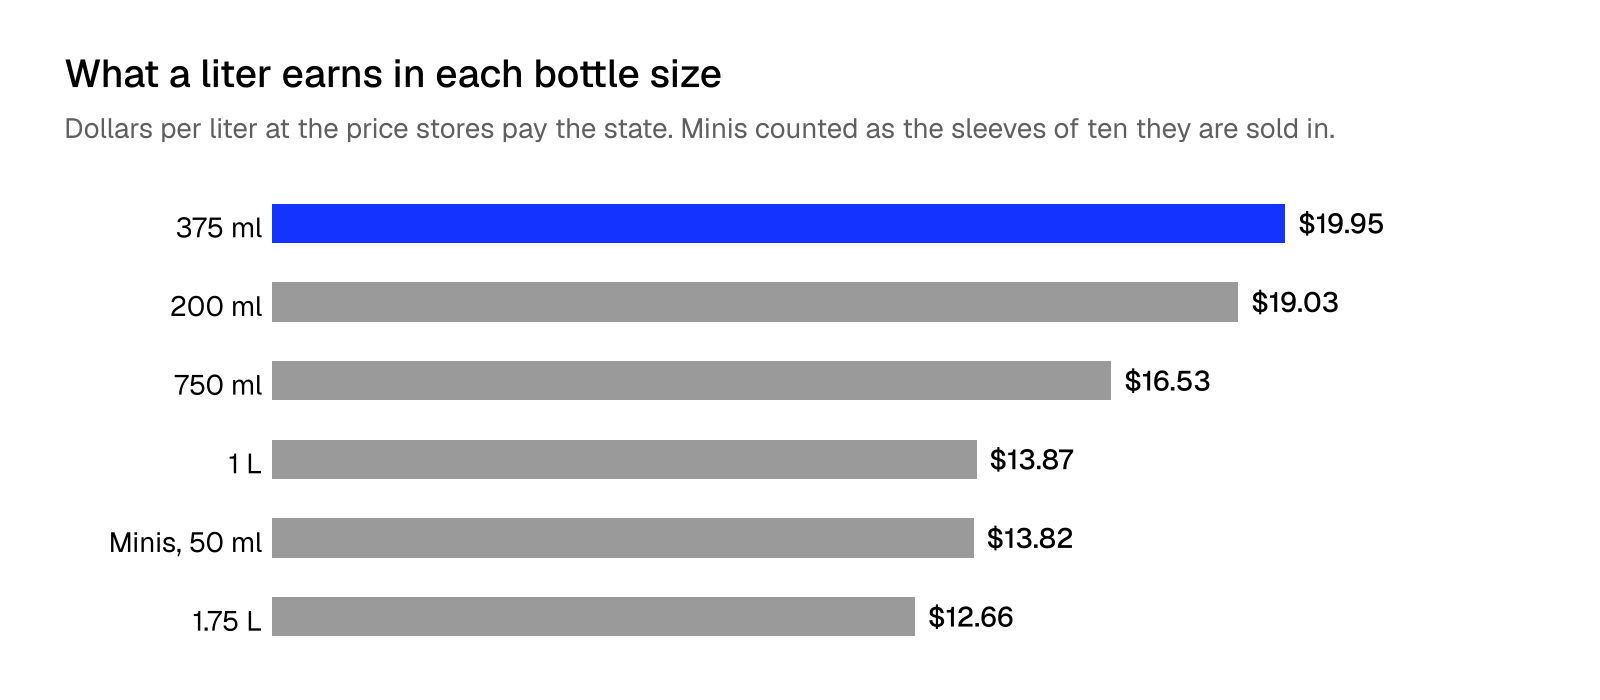

In [6]:
Image(charts.chart_per_liter(r, f), width=760)

Ten smallest sellers: $13.91 a liter.  Whole brand: $15.06 a liter.


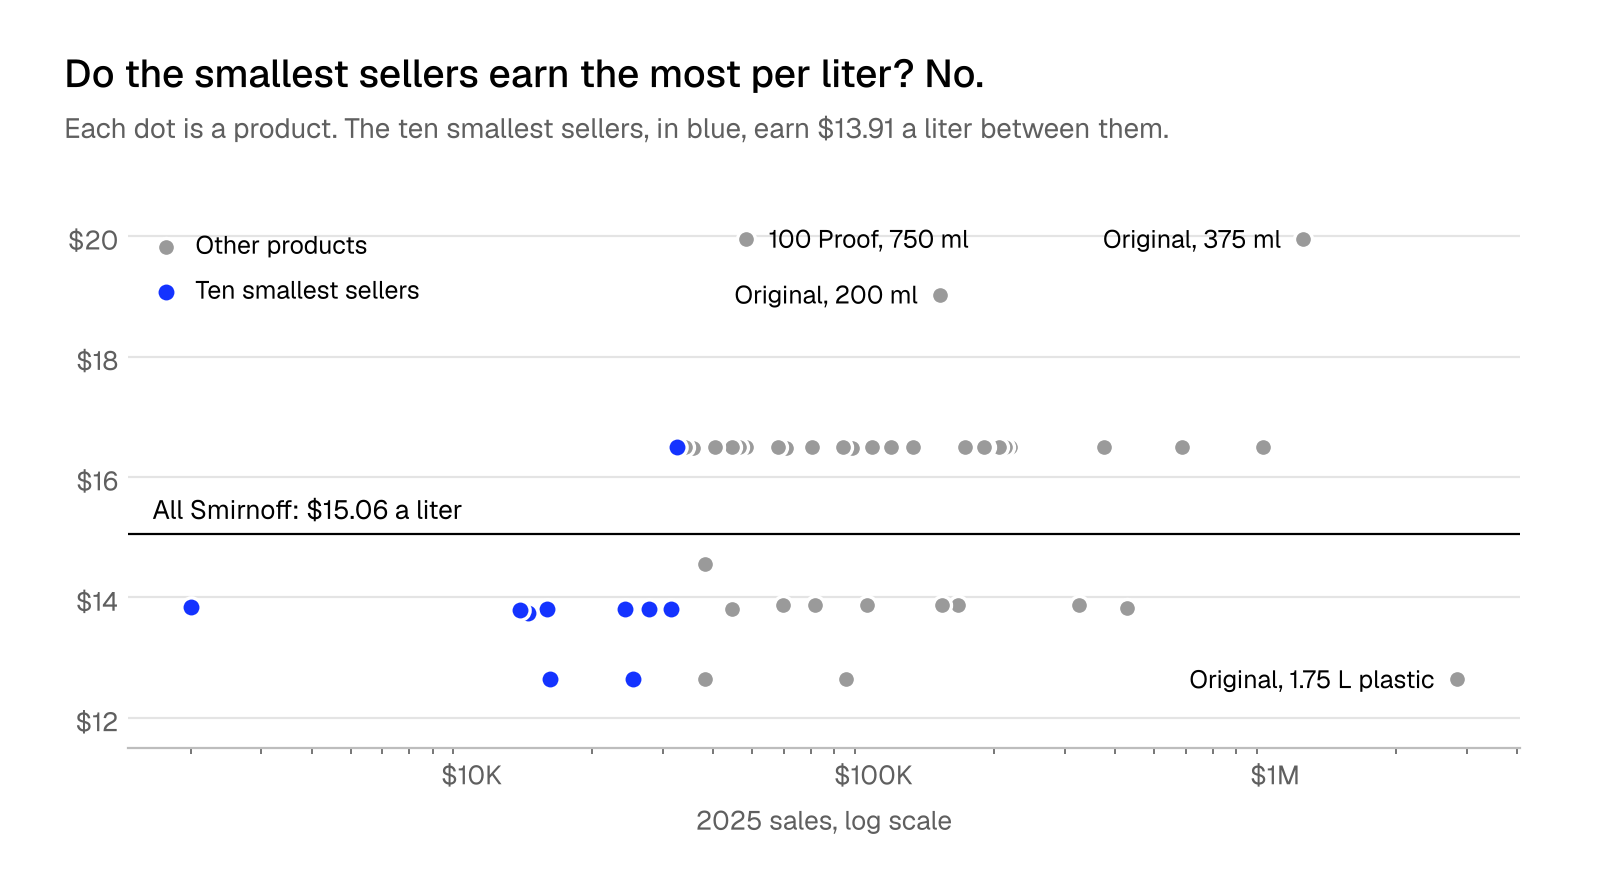

In [7]:
print(f"Ten smallest sellers: ${f['per_liter_smallest_all']:.2f} a liter.  Whole brand: ${f['per_liter_brand']:.2f} a liter.")
Image(charts.chart_small_vs_price(r, f), width=760)

## Step 4. Set aside what one year cannot judge

In [8]:
aside = p[p["is_new"] | p["is_seasonal"]][["name", "sales", "sales_2024", "first_sale", "last_sale", "months", "is_new", "is_seasonal"]]
print(f"{len(r['judged'])} products left to judge. Their ten smallest: ${f['smallest_sales']:,.0f}, {f['smallest_share']:.1%} of sales.")
aside.style.format({"sales": "${:,.0f}", "sales_2024": "${:,.0f}"})

46 products left to judge. Their ten smallest: $249,977, 2.5% of sales.


,name,sales,sales_2024,first_sale,last_sale,months,is_new,is_seasonal
item_no,,,,,,,,
77903,"Peppermint Twist, 750 ml","$88,600","$55,735",2025-08-07,2025-12-23,5,False,True
78556,"Electric Guava, 750 ml","$40,340",$0,2025-05-14,2025-12-31,8,True,False
102694,"Variety Pack, minis x120","$31,330",$0,2025-06-19,2025-12-26,7,True,False
77681,"Kissed Caramel, minis x10","$13,853",$0,2025-01-29,2025-12-31,9,True,False
78557,"Electric Guava, minis x10","$13,205",$0,2025-05-14,2025-12-26,8,True,False


## Step 5. Few stores, or slow everywhere?

In [9]:
top = p.sort_values("per_store", ascending=False)[["name", "rank", "stores", "per_store"]].head(6)
small = p.loc[r["smallest"], ["name", "rank", "stores", "per_store"]]
pd.concat({"highest per store": top, "ten smallest sellers": small}).style.format({"per_store": "${:,.0f}"})

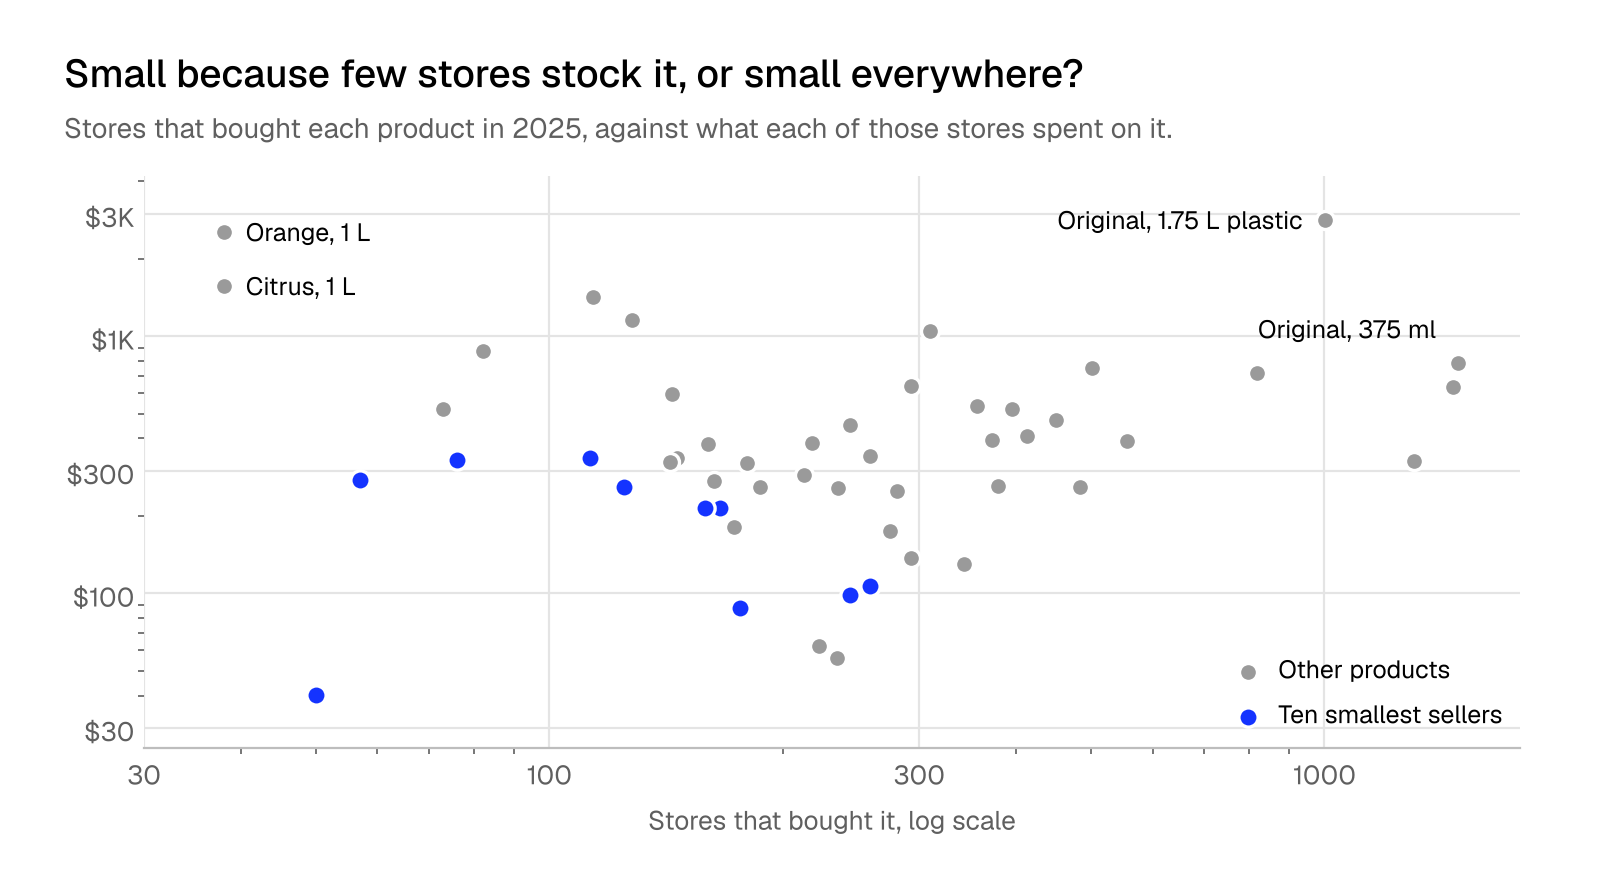

In [10]:
Image(charts.chart_reach(r, f), width=760)

## Step 6. Ask where the buyer goes

For each store that bought a product: does it stock the same flavor in another size, only other Smirnoff, or nothing else from the brand? Then the estimated loss under three assumptions about how much demand stays.

In [11]:
for name, cut in r["cuts"].items():
    print(f"{name}:")
    for k in cut:
        print(f"   {p.loc[k, 'name']:40s} ${p.loc[k, 'sales']:>9,.0f}")

Ten smallest sellers:
   Spicy Tamarind, minis x10                $    2,007
   Peach Lemonade, minis x10                $   15,399
   Peach Lemonade, 1.75 L                   $   15,712
   Blue Raspberry Lemonade, minis x10       $   24,082
   Blue Raspberry Lemonade, 1.75 L          $   25,175
   Pink Lemonade, minis x10                 $   27,596
   Zero Sugar Watermelon & Mint, 750 ml     $   32,406
   Lime, 750 ml                             $   33,979
   Orange, 750 ml                           $   35,508
   Pink Lemonade, 1.75 L                    $   38,114
Ten with the lowest loss:
   Spicy Tamarind, minis x10                $    2,007
   Peach Lemonade, 1.75 L                   $   15,712
   Peach Lemonade, minis x10                $   15,399
   Blue Raspberry Lemonade, 1.75 L          $   25,175
   Blue Raspberry Lemonade, minis x10       $   24,082
   Pink Lemonade, minis x10                 $   27,596
   Pink Lemonade, 1.75 L                    $   38,114
   100 Proof, 1.7

In [12]:
rows = {}
for name, cut in r["cuts"].items():
    w = c.where_buyers_can_go(r["st"], cut)
    rows[name] = w.groupby("kind")["sales"].sum() / w["sales"].sum()
pd.DataFrame(rows).T[["same flavor", "other", "nowhere"]].style.format("{:.1%}")

kind,same flavor,other,nowhere
Ten smallest sellers,34.9%,64.8%,0.3%
Ten with the lowest loss,53.6%,46.1%,0.3%
The nine that stopped selling,11.9%,87.7%,0.4%


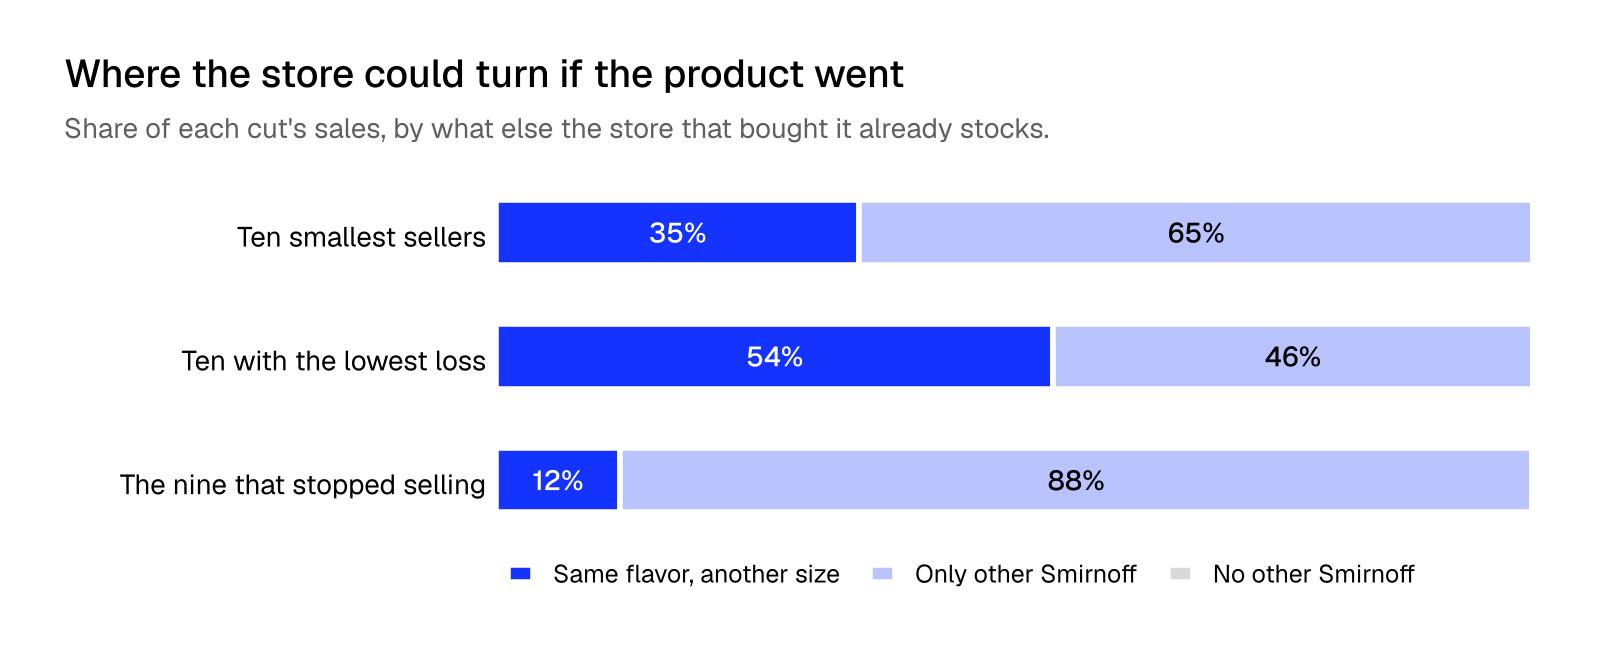

In [13]:
Image(charts.chart_where(r, f), width=760)

In [14]:
print("Share of liters assumed to stay (same flavor in another size, only other Smirnoff):", c.SCENARIOS)
r["table"].style.format({"sales removed": "${:,.0f}", "Nothing moves": "${:,.0f}", "Some moves": "${:,.0f}", "Most moves": "${:,.0f}"})

Share of liters assumed to stay (same flavor in another size, only other Smirnoff): {'Nothing moves': (0.0, 0.0), 'Some moves': (0.5, 0.25), 'Most moves': (0.8, 0.5)}


,products,sales removed,Nothing moves,Some moves,Most moves
cut,,,,,
Ten smallest sellers,10,"$249,977","$249,977","$158,259","$88,340"
Ten with the lowest loss,10,"$263,264","$263,264","$144,940","$61,781"
The nine that stopped selling,9,"$238,698","$238,698","$174,023","$116,352"


## What actually happened

A product counts as gone if it had no sale after February 2026. The 2026 data runs through October 30.

In [15]:
gone = p.loc[r["gone"], ["name", "rank", "sales", "is_new", "last_sale_2026", "sales_2026"]].sort_values("rank")
print(f"{f['n_gone']} products gone. In the plain ten smallest: {f['gone_in_smallest_all']}.")
print(f"Old enough to judge: {f['gone_judged']}. On the sales-rank list: {f['gone_in_smallest']}. On the lowest-loss list: {f['gone_in_lowest']}.")
gone.style.format({"sales": "${:,.0f}", "sales_2026": "${:,.0f}"})

9 products gone. In the plain ten smallest: 6.
Old enough to judge: 6. On the sales-rank list: 5. On the lowest-loss list: 4.


,name,rank,sales,is_new,last_sale_2026,sales_2026
item_no,,,,,,
77714,"Pineapple, 750 ml",36,"$44,544",False,2026-02-26,"$5,554"
78556,"Electric Guava, 750 ml",37,"$40,340",True,2026-02-12,"$1,980"
77688,"Lime, 750 ml",41,"$33,979",False,2026-02-12,"$2,009"
78079,"Zero Sugar Watermelon & Mint, 750 ml",42,"$32,406",False,2026-01-02,$12
102694,"Variety Pack, minis x120",43,"$31,330",True,2026-02-02,"$2,384"
76829,"Blue Raspberry Lemonade, 1.75 L",45,"$25,175",False,nan,$0
78291,"Peach Lemonade, 1.75 L",47,"$15,712",False,nan,$0
78557,"Electric Guava, minis x10",50,"$13,205",True,nan,$0
77987,"Spicy Tamarind, minis x10",51,"$2,007",False,nan,$0


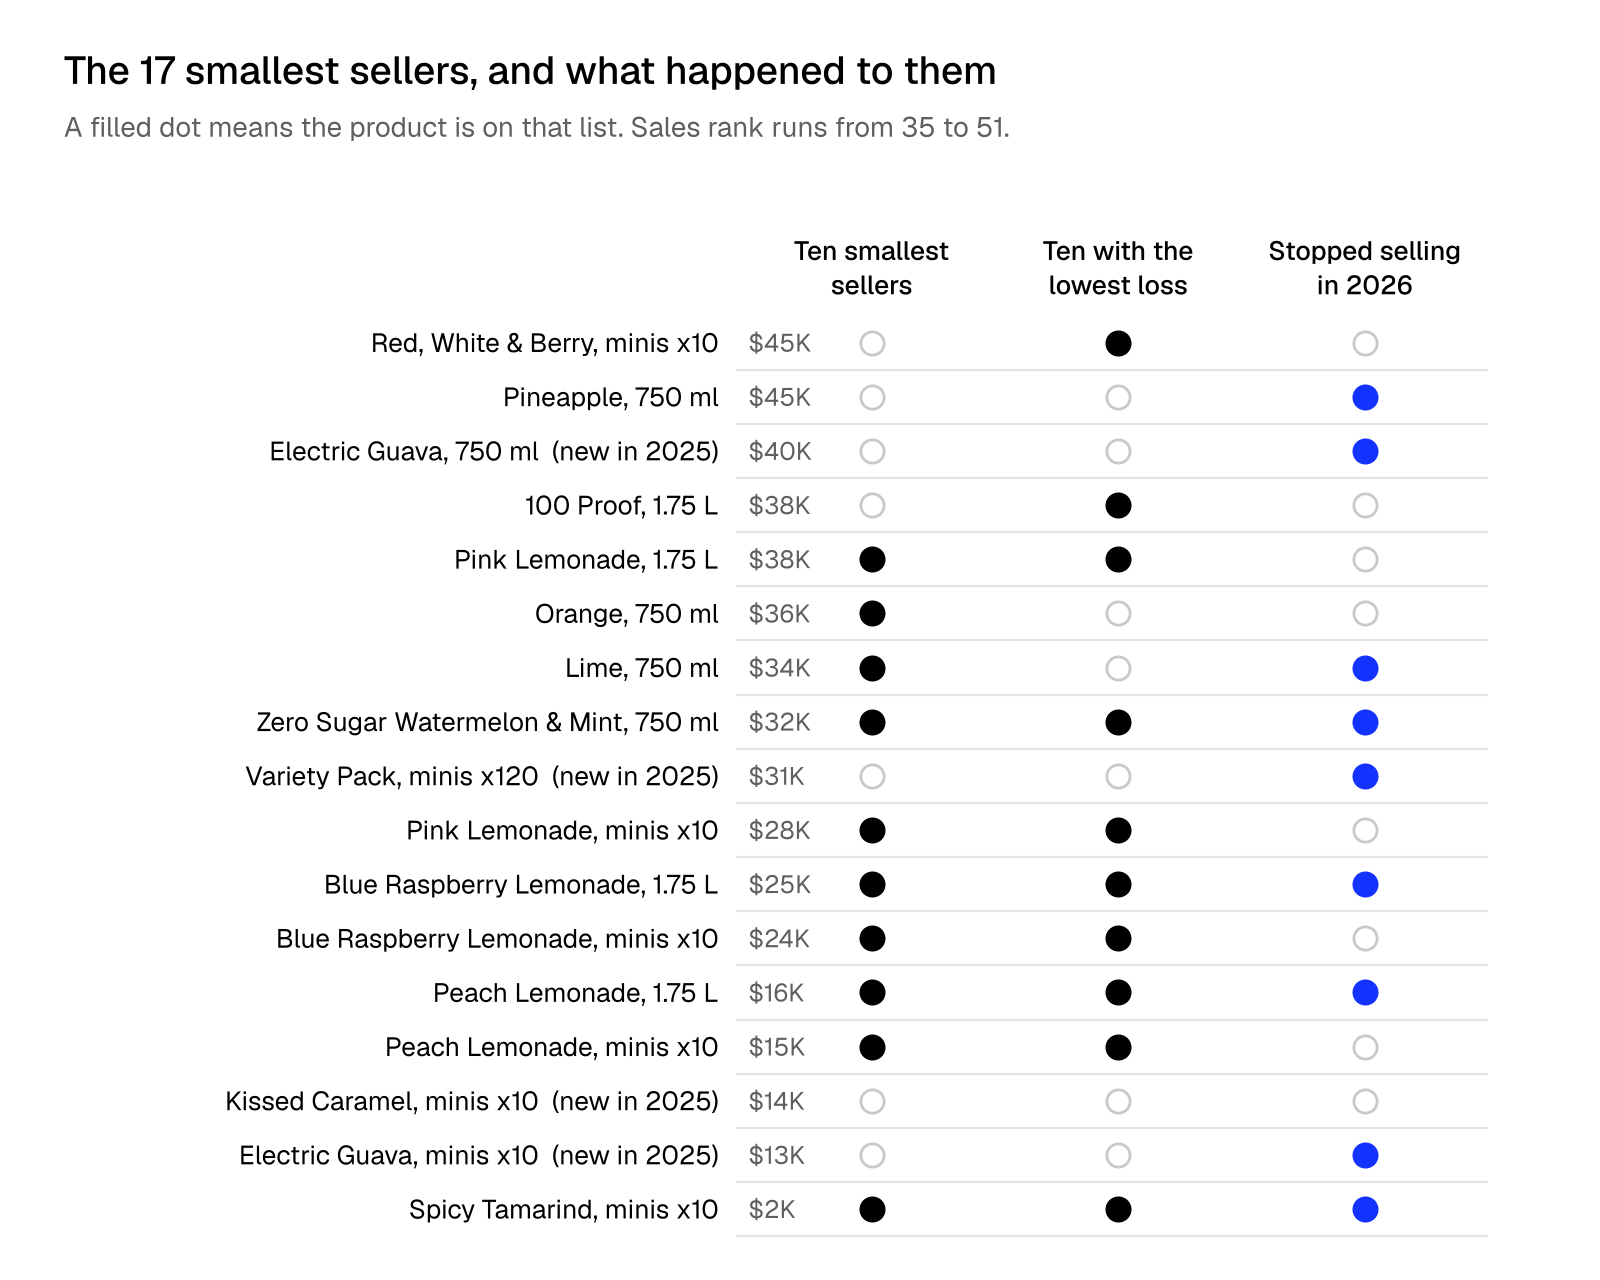

In [16]:
Image(charts.chart_outcome(r, f), width=760)